# 🍺 Atividade Prática: Medalhão (Bronze → Prata → Ouro) com Spark e Delta Lake

**Disciplina:** Arquitetura de Coleta e Armazenamento de Dados (Object Storage + Spark)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wuldson-franco/arqu_coleta_dados_pos_unipe/blob/main/Atividade_Pratica_Spark/atividade_storage_breweries.ipynb) -> *CLIQUE AQUI PARA ABRIR O ARQUIVO NO SEU GOOGLE COLAB*

| | |
|---|---|
| **Nome do aluno** | José Nunes |
| **Data** | 17/10/2026 |

---

## Como fazer esta atividade

1. **Não edite este arquivo diretamente.** Vá em **Arquivo → Salvar uma cópia no Drive** e trabalhe na sua cópia.
2. Rode as células **em ordem**, de cima para baixo. Se der erro estranho, use **Ambiente de execução → Reiniciar sessão** e rode tudo de novo.
3. As perguntas marcadas com ✏️ são **abertas**: responda com as suas palavras, na célula de texto logo abaixo da pergunta.
4. Ao terminar, rode a célula final de **autoverificação** e envie o link da sua cópia diretamente do seu repositorio no Github (com permissão de leitura).

## O que vamos construir

```
 arquivo .parquet  ──►  BRONZE (Delta)  ──►  PRATA (Delta)  ──►  OURO (Delta)
   (dado cru)           dado como chegou     limpo e corrigido    agregado p/ o negócio
```

**Pergunta de negócio:** _"Quais tipos de cervejaria existem por cidade, província e país?"_

> 💡 **Sobre o uso de IA:** você pode usar IA como apoio (Claude, ChatGPT, Gemini, Copilot…). Mas **você** responde pelo resultado. Duas perguntas no final pedem que você reflita sobre esse uso, então guarde o que perguntou e o que você precisou corrigir.

## 0. Preparando o ambiente

Vamos instalar o Java, o PySpark e o Delta Lake. As versões precisam combinar entre si (PySpark 3.5.1 ↔ Delta 3.1.0). **Esta célula demora 1 a 2 minutos.**

In [1]:
%%bash

# Instalar Java
apt-get update --fix-missing
apt-get install openjdk-8-jdk-headless -qq > /dev/null

# Instalar PySpark e Delta Lake (versões compatíveis para evitar conflito de dependências)
pip uninstall -y delta-spark
pip install -q pyspark==3.5.1
pip install -q delta-spark==3.1.0

Get:1 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]
Get:4 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:7 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,411 kB]
Get:8 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,549 kB]
Get:9 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:11 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.3 kB]
Get:12 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:13 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Pack

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.


In [2]:
import os, logging, requests

# Apontamos o Spark para o Java que acabamos de instalar
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-8-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

from pyspark.sql import SparkSession, functions as F
from delta import configure_spark_with_delta_pip

builder = (
    SparkSession.builder.appName("Atividade_Medalhao_Breweries")
    .master("local[*]")
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
    .config("spark.sql.repl.eagerEval.enabled", True)
)
spark = configure_spark_with_delta_pip(builder).getOrCreate()
print("Spark", spark.version, "pronto ✅")

# Nosso "data lake" de brincadeira: pastas no disco da VM do Colab
base_path = "/content/datalake"
for camada in ["bronze", "silver", "gold"]:
    os.makedirs(os.path.join(base_path, camada), exist_ok=True)
print("Pastas criadas em", base_path)

Spark 3.5.1 pronto ✅
Pastas criadas em /content/datalake


---
## 1. 🥉 Camada Bronze

Vamos baixar o arquivo cru e guardá-lo na Bronze **sem alterar nada**, só convertendo para o formato Delta.

In [3]:
parquet_url  = "https://github.com/wuldson-franco/breweries_case/raw/main/analises/bs_bronze.parquet"
parquet_path = os.path.join(base_path, "bronze", "bs_bronze.parquet")
delta_bronze = os.path.join(base_path, "bronze", "bs_bronze_delta")

# Baixar o arquivo Parquet (só se ainda não existir)
if not os.path.exists(parquet_path):
    response = requests.get(parquet_url)
    response.raise_for_status()
    with open(parquet_path, "wb") as f:
        f.write(response.content)

df = spark.read.parquet(parquet_path)

# mode("overwrite") permite rodar a célula mais de uma vez sem erro
df.write.format("delta").mode("overwrite").save(delta_bronze)

print("Linhas na Bronze:", spark.read.format("delta").load(delta_bronze).count())

Linhas na Bronze: 50


Agora vamos **olhar por dentro** do que foi gravado. Em um bucket de object storage, cada arquivo seria um _objeto_ e o caminho completo seria a sua _chave_.

In [4]:
# Lista tudo o que existe dentro da Bronze Delta (caminho relativo e tamanho)
for raiz, _, arquivos in os.walk(delta_bronze):
    for nome in sorted(arquivos):
        caminho = os.path.join(raiz, nome)
        print(f"{os.path.relpath(caminho, base_path):<85} {os.path.getsize(caminho):>10,} bytes")

bronze/bs_bronze_delta/.part-00000-d7bfe432-40d5-486c-91f4-5ce4df5055e5-c000.snappy.parquet.crc        112 bytes
bronze/bs_bronze_delta/part-00000-d7bfe432-40d5-486c-91f4-5ce4df5055e5-c000.snappy.parquet     12,911 bytes
bronze/bs_bronze_delta/_delta_log/.00000000000000000000.json.crc                              36 bytes
bronze/bs_bronze_delta/_delta_log/00000000000000000000.json                                3,303 bytes


### ✏️ Q1. Olhando por dentro da Bronze
Observe a listagem acima. **(a)** Que tipos de arquivo você vê e para que serve cada um? **(b)** Se essa pasta estivesse em um bucket S3/MinIO, o que seriam a _chave_ e o _objeto_ de um desses arquivos?

**✏️ Sua resposta:**

**(a)** Dentro da pasta `bs_bronze_delta` aparecem três tipos de arquivo:
- **`part-0000…snappy.parquet`**: são os **dados** de fato, em formato colunar e comprimidos com Snappy. O Spark grava um arquivo por partição do DataFrame.
- **`_delta_log/00000000000000000000.json`**: é o **log de transações** do Delta. Cada gravação gera um JSON novo (versão 0, 1, 2…) dizendo quais arquivos Parquet foram adicionados ou removidos, o schema e a operação feita. É ele que transforma "uma pasta com Parquet" em uma **tabela**.
- **`.crc`** (os que começam com ponto): são checksums que o Hadoop grava no disco local para conferir a integridade de cada arquivo. Em um bucket S3/MinIO eles não aparecem.

**(b)** Em um bucket, cada arquivo seria um **objeto** (o conteúdo em bytes mais os metadados) e o caminho inteiro seria a **chave**. Por exemplo, no bucket `warehouse` a chave seria `bronze/bs_bronze_delta/_delta_log/00000000000000000000.json`, e o objeto é o próprio JSON. A "pasta" `bronze/bs_bronze_delta/` não existe sozinha: é só o começo (prefixo) da chave.

### ✏️ Q2. Por que Bronze e por que Delta?
**(a)** Por que a Bronze deve guardar o dado **como ele chegou**, sem corrigir nada? **(b)** Qual problema o Delta resolve que um monte de arquivos Parquet soltos no storage não resolve?

**✏️ Sua resposta:**

**(a)** A Bronze é a **prova do que a fonte mandou**. Se eu já corrigisse na entrada e a correção estivesse errada (um endereço mal pesquisado, uma regra mal escrita), eu perderia o original e não teria como refazer. Guardando cru, posso reprocessar a Prata quantas vezes precisar, auditar ("o dado veio errado da fonte ou o erro foi nosso?") e mudar as regras sem pedir o arquivo de novo para a origem. É a ideia do ELT: carrega primeiro, transforma depois.

**(b)** Um monte de Parquet solto não sabe o que é "a tabela". Se um job cai no meio de uma gravação, quem lê vê metade dos arquivos novos misturados com os velhos. Não há como atualizar só algumas linhas, nem saber qual era o estado de ontem. O Delta resolve isso com o `_delta_log`:
- transações **ACID**: ou a gravação inteira aparece, ou nada aparece;
- versões e **time travel**;
- `MERGE`, `UPDATE` e `DELETE`;
- controle e evolução de **schema**.

Tudo isso por cima dos mesmos arquivos Parquet.

---
## 2. 🥈 Camada Prata

Aqui o dado é inspecionado, limpo e corrigido. Resolva os passos na ordem.

**2.1** Exiba o _schema_ das colunas com `printSchema`.

In [5]:
# Lê a Bronze (Delta) e mostra o schema
df = spark.read.format("delta").load(delta_bronze)
df.printSchema()
print("Linhas na Bronze:", df.count())

root
 |-- id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- brewery_type: string (nullable = true)
 |-- address_1: string (nullable = true)
 |-- address_2: string (nullable = true)
 |-- address_3: integer (nullable = true)
 |-- city: string (nullable = true)
 |-- state_province: string (nullable = true)
 |-- postal_code: string (nullable = true)
 |-- country: string (nullable = true)
 |-- longitude: string (nullable = true)
 |-- latitude: string (nullable = true)
 |-- phone: string (nullable = true)
 |-- website_url: string (nullable = true)
 |-- state: string (nullable = true)
 |-- street: string (nullable = true)

Linhas na Bronze: 50


**2.2** Faça um `select` do país para verificar **quais países constam na nossa base**. Mostre também **quantas cervejarias** há em cada um.

In [6]:
# Quais países constam na base?
df.select("country").distinct().orderBy("country").show(truncate=False)

# Quantas cervejarias há em cada país
(df.groupBy("country")
   .agg(F.count("*").alias("qtd_cervejarias"))
   .orderBy(F.desc("qtd_cervejarias"), "country")
   .show(truncate=False))

+-------------+
|country      |
+-------------+
|Ireland      |
|United States|
+-------------+

+-------------+---------------+
|country      |qtd_cervejarias|
+-------------+---------------+
|United States|49             |
|Ireland      |1              |
+-------------+---------------+



**2.3** Descubra **quais cervejarias estão com o endereço faltante**.

> Dica: "faltante" pode ser `null` **e também** texto vazio (`""`) ou só espaços. Confira os dois casos. Qual é a coluna de endereço? Veja no `printSchema`.

In [7]:
# "Faltante" = null OU texto vazio OU só espaços (trim(...) == "")
endereco_faltante = F.col("address_1").isNull() | (F.trim(F.col("address_1")) == "")

df_sem_endereco = df.filter(endereco_faltante)
print("Cervejarias com endereço faltante:", df_sem_endereco.count())
df_sem_endereco.select("id", "name", "brewery_type", "city", "state_province",
                       "postal_code", "country", "address_1").show(truncate=False)

Cervejarias com endereço faltante: 3
+------------------------------------+---------------------------------------------+------------+---------+--------------+-----------+-------------+---------+
|id                                  |name                                         |brewery_type|city     |state_province|postal_code|country      |address_1|
+------------------------------------+---------------------------------------------+------------+---------+--------------+-----------+-------------+---------+
|0faa0fb2-fffa-416d-9eab-46f67477c8ef|12 West Brewing Company - Production Facility|micro       |Mesa     |Arizona       |85207      |United States|NULL     |
|b7b68d22-5045-4501-b9bf-ec94946eaffc|14 Lakes Brewery                             |micro       |Crosslake|Minnesota     |56442      |United States|NULL     |
|fe6b9893-b93e-43d5-a9f6-3e0c89a3f13c|1850 Brewing Company                         |micro       |Mariposa |California    |95338      |United States|NULL     |
+--------

**2.4** Pesquise na internet **qual é o endereço real** dessas cervejarias e inclua-os nos campos faltantes usando `when` / `otherwise`.

Crie também uma coluna `address_fonte` dizendo **de onde veio o dado** (por exemplo: `"original"` ou `"pesquisa manual"`). Guarde esta ideia: ela será cobrada na pergunta Q3.

> Estrutura do `when` (os valores abaixo são só um **exemplo**, troque pelos seus):
> ```python
> df_silver = df.withColumn(
>     "address_1",
>     F.when(F.col("id") == "ID_DA_CERVEJARIA", "Endereço encontrado").otherwise(F.col("address_1"))
> )
> ```

In [8]:
# Endereços pesquisados manualmente (17/10/2026). Fontes:
#  - 12 West Brewing (Production Facility): brewerysearch.com e breweriesnearby.com -> 7733 E McDowell Rd, Mesa, AZ 85207
#  - 14 Lakes Brewery: brewbound.com -> 36846 County Road 66, Crosslake, MN 56442
#  - 1850 Brewing Company: yosemite.com (1850 Restaurant, mesmo site da base) -> 5114 Highway 140, Mariposa, CA 95338
ID_12_WEST  = "0faa0fb2-fffa-416d-9eab-46f67477c8ef"
ID_14_LAKES = "b7b68d22-5045-4501-b9bf-ec94946eaffc"
ID_1850     = "fe6b9893-b93e-43d5-a9f6-3e0c89a3f13c"
ids_pesquisados = [ID_12_WEST, ID_14_LAKES, ID_1850]

df_silver = (
    df
    # 1) linhagem: marca a ORIGEM do endereço ANTES de corrigir (depois da correção não dá mais para saber)
    .withColumn("address_fonte",
        F.when(endereco_faltante & F.col("id").isin(ids_pesquisados), F.lit("pesquisa manual"))
         .when(endereco_faltante, F.lit("faltante"))
         .otherwise(F.lit("original")))
    .withColumn("address_fonte_url",
        F.when(F.col("id") == ID_12_WEST,  F.lit("https://brewerysearch.com/arizona/mesa/12-west-brewing-company-production-facility"))
         .when(F.col("id") == ID_14_LAKES, F.lit("https://www.brewbound.com/breweries/14-lakes-brewery"))
         .when(F.col("id") == ID_1850,     F.lit("https://www.yosemite.com/things-to-do/restaurants/1850-restaurant/")))
    # 2) correção com when/otherwise (só onde o endereço estava faltando)
    .withColumn("address_1",
        F.when(endereco_faltante & (F.col("id") == ID_12_WEST),  F.lit("7733 E McDowell Rd"))
         .when(endereco_faltante & (F.col("id") == ID_14_LAKES), F.lit("36846 County Road 66"))
         .when(endereco_faltante & (F.col("id") == ID_1850),     F.lit("5114 Highway 140"))
         .otherwise(F.col("address_1")))
    # na base, "street" repete o address_1; mantemos as duas coerentes
    .withColumn("street",
        F.when(F.col("address_fonte") == "pesquisa manual", F.col("address_1")).otherwise(F.col("street")))
    # 3) tipagem: coordenadas chegam como texto na Bronze
    .withColumn("longitude", F.col("longitude").cast("double"))
    .withColumn("latitude",  F.col("latitude").cast("double"))
)

df_silver.filter(F.col("address_fonte") != "original") \
         .select("name", "city", "state_province", "address_1", "address_fonte").show(truncate=False)

+---------------------------------------------+---------+--------------+--------------------+---------------+
|name                                         |city     |state_province|address_1           |address_fonte  |
+---------------------------------------------+---------+--------------+--------------------+---------------+
|12 West Brewing Company - Production Facility|Mesa     |Arizona       |7733 E McDowell Rd  |pesquisa manual|
|14 Lakes Brewery                             |Crosslake|Minnesota     |36846 County Road 66|pesquisa manual|
|1850 Brewing Company                         |Mariposa |California    |5114 Highway 140    |pesquisa manual|
+---------------------------------------------+---------+--------------+--------------------+---------------+



**2.5** Verificações de qualidade. Responda com código:
- Existem `id` **duplicados**?
- Existem nulos em `brewery_type`, `city` ou `country`?
- Depois da sua correção, ainda sobra algum endereço faltante?

In [9]:
# (a) ids duplicados?
total = df_silver.count()
ids_distintos = df_silver.select("id").distinct().count()
print(f"Linhas: {total} | ids distintos: {ids_distintos} | duplicados: {total - ids_distintos}")
df_silver.groupBy("id").count().filter("count > 1").show()

# (b) nulos (ou vazios) nas colunas de negócio
for coluna in ["brewery_type", "city", "country"]:
    n = df_silver.filter(F.col(coluna).isNull() | (F.trim(F.col(coluna)) == "")).count()
    print(f"Nulos/vazios em {coluna}: {n}")

# (c) ainda sobra endereço faltante depois da correção?
restantes = df_silver.filter(F.col("address_1").isNull() | (F.trim(F.col("address_1")) == "")).count()
print("Endereços faltantes após a correção:", restantes)

# resumo da linhagem do endereço
df_silver.groupBy("address_fonte").count().show()

Linhas: 50 | ids distintos: 50 | duplicados: 0
+---+-----+
| id|count|
+---+-----+
+---+-----+

Nulos/vazios em brewery_type: 0
Nulos/vazios em city: 0
Nulos/vazios em country: 0
Endereços faltantes após a correção: 0
+---------------+-----+
|  address_fonte|count|
+---------------+-----+
|       original|   47|
|pesquisa manual|    3|
+---------------+-----+



**2.6** Salve a Prata em **Delta**, em `silver/breweries_silver`, e depois leia de volta para conferir a contagem.

In [10]:
silver_path = os.path.join(base_path, "silver", "breweries_silver")

# gravar com mode("overwrite") (overwriteSchema porque a Prata ganhou colunas novas)
(df_silver.write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(silver_path))

# ler de volta e dar count
df_silver_lida = spark.read.format("delta").load(silver_path)
print("Linhas na Prata:", df_silver_lida.count())

Linhas na Prata: 50


### ✏️ Q3. Qualidade e governança
**(a)** Você corrigiu os endereços na mão, com `when/otherwise`. Isso funcionaria para 5 milhões de registros com problemas? Que alternativa você proporia? **(b)** Para que serve a coluna `address_fonte` que você criou? Relacione com os conceitos de **linhagem** e **confiança no dado**.

**✏️ Sua resposta:**

**(a)** Não. Com 3 registros, pesquisar à mão e escrever um `when` por id funciona. Com 5 milhões, vira código gigante, impossível de manter e sem rastreabilidade. Eu faria assim:
- montaria uma **tabela de referência**, por exemplo de endereços vindos de uma API de geocodificação (Google, OpenStreetMap/Nominatim) usando a latitude/longitude ou o CEP que a base já tem, ou de um cadastro oficial;
- faria um **join/MERGE** dela com a Prata, em vez de um `when` por registro;
- o que não casar com a referência não seria inventado: iria para uma **tabela de quarentena** para revisão;
- a correção ficaria como uma **regra no pipeline**, reaproveitada a cada carga, e não como um ajuste manual.

**(b)** A `address_fonte` diz **de onde veio cada endereço**: `original` (veio da fonte) ou `pesquisa manual` (fui eu que preenchi). Isso é **linhagem** no nível da coluna. Quem usar a tabela sabe que 47 endereços vieram da origem e 3 foram completados por pesquisa, e pode decidir se confia neles para, por exemplo, mandar uma entrega. Também deixei a `address_fonte_url` com o link da fonte. Se alguém questionar um endereço, dá para conferir de onde ele saiu. Sem isso, o dado corrigido fica indistinguível do original, e a **confiança** na tabela toda cai.

---
## 3. 🥇 Camada Ouro

Vamos responder à pergunta de negócio: **"Quais tipos de cervejaria por cidade, província e país?"**

Abaixo está a função de agregação, escrita em **pandas**. Ela não roda direto em um DataFrame do Spark. Sua tarefa é **convertê-la para Spark**.

In [11]:
# ATENÇÃO: esta função é pandas. Não rode com o DataFrame do Spark.
def data_aggregation(df):
    try:
        # Agrupando por tipo de cervejaria e localização
        aggregated_df = df.groupby(['brewery_type', 'city', 'state_province', 'country']).size().reset_index(name='brewery_count')
        return aggregated_df
    except Exception as e:
        logging.error(f"Erro ao realizar a agregação de dados: {e}")
        raise

In [12]:
# Versão Spark da função pandas.
# Detalhe: groupby() do pandas DESCARTA chaves nulas por padrão (dropna=True); o groupBy do Spark
# NÃO descarta (cria um grupo "null"). O na.drop() deixa o resultado equivalente ao do pandas.
CHAVES = ["brewery_type", "city", "state_province", "country"]

def data_aggregation_spark(df):
    try:
        aggregated_df = (df.na.drop(subset=CHAVES)
                           .groupBy(*CHAVES)
                           .agg(F.count("*").alias("brewery_count")))
        return aggregated_df
    except Exception as e:
        logging.error(f"Erro ao realizar a agregação de dados: {e}")
        raise

Agora aplique a função na **Prata**, salve o resultado em **Delta** em `gold/breweries_por_local` e mostre as 10 linhas com maior `brewery_count`.

In [13]:
gold_path = os.path.join(base_path, "gold", "breweries_por_local")

df_prata = spark.read.format("delta").load(silver_path)
df_gold = data_aggregation_spark(df_prata)

df_gold.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(gold_path)

df_gold_lida = spark.read.format("delta").load(gold_path)
print("Linhas na Ouro:", df_gold_lida.count(), "| soma de brewery_count:",
      df_gold_lida.agg(F.sum("brewery_count")).first()[0], "(deve bater com a Prata)")

# Top 10 por brewery_count
(df_gold_lida.orderBy(F.desc("brewery_count"), "country", "state_province", "city")
             .show(10, truncate=False))

Linhas na Ouro: 48 | soma de brewery_count: 50 (deve bater com a Prata)
+------------+----------------+--------------+-------------+-------------+
|brewery_type|city            |state_province|country      |brewery_count|
+------------+----------------+--------------+-------------+-------------+
|large       |Bend            |Oregon        |United States|3            |
|micro       |Killeshin       |Laois         |Ireland      |1            |
|micro       |Gilbert         |Arizona       |United States|1            |
|micro       |Mesa            |Arizona       |United States|1            |
|micro       |Tucson          |Arizona       |United States|1            |
|micro       |Mariposa        |California    |United States|1            |
|closed      |Petaluma        |California    |United States|1            |
|large       |San Diego       |California    |United States|1            |
|micro       |Westlake Village|California    |United States|1            |
|micro       |Castle Rock   

### ✏️ Q4. Para quem é a Ouro?
**(a)** Por que não deixar o dashboard ler a Prata e fazer essa agregação na hora? **(b)** Cite dois consumidores possíveis dessa tabela Ouro e o que cada um faria com ela.

**✏️ Sua resposta:**

**(a)** Por três motivos:
- **Custo e tempo:** cada vez que alguém abrisse o painel, o motor teria de ler a Prata inteira e reagrupar tudo, e o `groupBy` gera *shuffle*. Com 50 linhas não importa, mas com milhões de linhas e dezenas de usuários fica lento e caro.
- **Uma definição só:** se a regra de agregação mora dentro de cada painel, cada analista pode fazer de um jeito e aparecem números diferentes para a mesma pergunta. A Ouro calcula uma vez, com regra versionada, e todos leem o mesmo resultado.
- **Contrato:** a Ouro tem um consumidor e uma pergunta claros. A Prata pode mudar por dentro (colunas novas, ajustes) sem quebrar o painel.

**(b)** Dois consumidores possíveis:
- **Time comercial ou de marketing de um fornecedor (malte, lúpulo, latas):** filtraria por estado e por tipo `micro`/`brewpub` para ver onde há concentração de clientes potenciais e planejar rota de vendedores ou campanhas regionais.
- **Um analista de mercado ou um investidor:** usaria a contagem por cidade e tipo para mapear saturação ("Bend tem 3 cervejarias *large*") ou achar cidades sem cervejaria para abrir um *brewpub*. Também poderia alimentar um painel no Metabase ou Power BI.

---
## 4. 🧊 Bônus Delta: viagem no tempo

O Delta guarda um **histórico de versões** no `_delta_log`. Rode a célula abaixo (ela já está pronta) e depois responda.

In [14]:
from delta.tables import DeltaTable

# Reescreve a Prata uma segunda vez (gera uma nova versão)
spark.read.format("delta").load(silver_path).write.format("delta").mode("overwrite").save(silver_path)

DeltaTable.forPath(spark, silver_path).history().select("version", "timestamp", "operation").show(truncate=False)

# Ler a versão 0, como estava no início
spark.read.format("delta").option("versionAsOf", 0).load(silver_path).count()

+-------+-----------------------+---------+
|version|timestamp              |operation|
+-------+-----------------------+---------+
|1      |2026-10-22 23:29:36.046|WRITE    |
|0      |2026-10-22 23:29:11.611|WRITE    |
+-------+-----------------------+---------+



50

### ✏️ Q5. Time travel
Em que situação real de trabalho você usaria `versionAsOf`? Dê um exemplo e explique **como isso é possível** em um storage onde os objetos não são editados no lugar.

**✏️ Sua resposta:**

**Exemplo:** na segunda-feira, um job da Prata roda com uma regra errada (digamos, um filtro que apagou todas as cervejarias `closed`) e o painel passa a mostrar números menores. Com `versionAsOf` eu:
- leio a versão de sexta (`spark.read.format("delta").option("versionAsOf", 3).load(...)`);
- comparo com a atual para descobrir exatamente o que sumiu;
- se for o caso, restauro a tabela (`RESTORE TABLE ... TO VERSION AS OF 3`).

Também serve para **auditoria** ("qual era o número que mandamos para a diretoria no dia 10?") e para **reproduzir** um treino de modelo de ML com o dado exato daquela data.

**Como é possível** sem editar objetos no lugar: o Delta **nunca altera** um Parquet existente. Uma "atualização" grava arquivos **novos** e um novo JSON no `_delta_log`, dizendo "a versão 1 é: remova o arquivo A, adicione o B". O arquivo A continua lá no storage. Ler a versão 0 é só seguir o JSON da versão 0, que aponta para os arquivos antigos. Por isso o time travel tem limite: quando o `VACUUM` apaga os arquivos antigos, aquelas versões deixam de poder ser lidas.

---
## 5. 🪣 Arquitetura: Object Storage

Estas perguntas não têm código. Elas medem se você entendeu **onde** e **como** os dados vivem.

### ✏️ Q6. Bucket, objeto e "pasta"
Explique a diferença entre **object storage** (S3, MinIO, GCS) e um **sistema de arquivos** comum. Por que se diz que em object storage "pasta não existe de verdade"? O que isso muda na hora de **renomear** ou **listar** dados?

**✏️ Sua resposta:**

Em um **sistema de arquivos** comum (o NTFS do Windows, por exemplo), existe uma árvore de verdade: cada pasta é um objeto com a lista dos seus filhos. Dá para abrir um arquivo e alterar um pedaço dele no meio.

No **object storage** (S3, MinIO, GCS), o espaço é **plano**: um bucket guarda pares *chave → objeto*. A chave `bronze/pedidos/part-001.parquet` é só um texto que, por convenção, tem `/`. O console **mostra** "pastas" porque agrupa as chaves pelo prefixo, mas não existe um objeto "pasta". Se eu apagar o último arquivo com aquele prefixo, a "pasta" some sozinha. Além disso, objetos são **imutáveis**: para mudar um byte, regravo o objeto inteiro.

O que isso muda na prática:
- **Renomear** uma "pasta" não é uma operação só. É copiar cada objeto para a chave nova e apagar a antiga, o que fica lento e **não é atômico** com milhares de arquivos. Por isso não se "renomeia pasta" em pipeline: escreve-se direto no destino final, e os formatos de tabela (Delta/Iceberg) usam o log de transações em vez de renomear.
- **Listar** é pedir as chaves que começam com um prefixo, em páginas (no S3, 1.000 por vez). Com muitos arquivos isso custa tempo e dinheiro (cada requisição é cobrada). Por isso o Delta/Iceberg lê o **log/manifesto** para saber quais arquivos compõem a tabela, em vez de listar o diretório.

### ✏️ Q7. Storage separado do processamento
Spark e object storage são sistemas separados, ligados pela rede. **Cite uma vantagem e um custo** (ou risco) dessa separação. Se quiser, comente também o problema dos "arquivos pequenos".

**✏️ Sua resposta:**

**Vantagem:** cada lado escala e **custa** por si. O dado fica guardado barato e durável no object storage, e o Spark só liga quando há trabalho: posso desligar o cluster à noite, subir um maior no fechamento do mês, ou ter vários motores (Spark, Trino, Python) lendo o **mesmo** dado. No Hadoop clássico, para ganhar disco eu tinha que comprar CPU junto.

**Custo/risco:** todo dado passa pela **rede**, então há latência, banda e (na nuvem) custo por requisição e por saída de dados. Não tenho mais a "localidade" do HDFS, em que o processamento rodava na mesma máquina do disco.

**Arquivos pequenos:** é onde essa separação mais dói. Cada arquivo custa pelo menos uma requisição HTTP (listar, abrir, ler o rodapé do Parquet). Mil arquivos de 10 KB demoram muito mais que um arquivo de 10 MB com os mesmos dados, e ainda incham os metadados da tabela. Acontece muito com streaming ou `partitionBy` exagerado. A solução é **compactar**: `OPTIMIZE` no Delta, `rewrite_data_files` no Iceberg, ou `coalesce`/`repartition` antes de gravar, mirando arquivos de ~128 MB a 1 GB.

### ✏️ Q8. Do Colab para o S3
Nesta atividade gravamos em `/content/datalake`, no disco da máquina do Colab. **(a)** O que acontece com esses dados quando a sessão do Colab é encerrada? **(b)** Se o destino fosse um bucket (`s3a://meu-bucket/bronze/...`), o que mudaria no código e na configuração? **(c)** Que cuidados de **segurança** você teria?

**✏️ Sua resposta:**

**(a)** Somem. O `/content` é o disco temporário da máquina virtual do Colab. Quando a sessão encerra (inatividade ou limite de tempo), a VM é descartada e o `datalake` vai junto. Por isso ali é "data lake de brincadeira": serve para aprender, não para guardar.

**(b)** No código, troco o caminho: `base_path = "s3a://meu-bucket"` e gravo em `s3a://meu-bucket/bronze/...`. A lógica do Spark não muda. Na configuração:
- incluo o conector **`hadoop-aws`** (e o AWS SDK) em `spark.jars.packages`, na versão que casa com o Hadoop do PySpark;
- configuro `spark.hadoop.fs.s3a.endpoint` (para o MinIO, `http://localhost:9000`), as credenciais `fs.s3a.access.key`/`fs.s3a.secret.key`, e `fs.s3a.path.style.access=true` no MinIO;
- com Delta, ajusto o `LogStore` se houver escritores concorrentes.

**(c)** Cuidados de segurança:
- **nunca** deixar chave e senha no notebook ou no Git: usar variáveis de ambiente, `.env` no `.gitignore` ou o gerenciador de segredos do Colab/da nuvem (na nuvem, de preferência um *IAM role*, sem chave nenhuma);
- dar **menor privilégio**: a credencial do pipeline só escreve nos prefixos dela, e o painel só lê a Ouro;
- bucket **privado**, com o acesso público bloqueado;
- **criptografia** em repouso e HTTPS em trânsito;
- versionamento ou retenção no bucket, para se proteger de apagar sem querer.

### ✏️ Q9. Projetando para escala
Imagine que a tabela Ouro passou a ter **500 milhões de linhas por ano**. Como você organizaria os arquivos no storage (formato, particionamento, tamanho dos arquivos)? Justifique pensando em **quem consulta** e **com que frequência**.

**✏️ Sua resposta:**

- **Formato:** Delta (ou Iceberg) sobre **Parquet com compressão** (Snappy/ZSTD). É colunar: quem pergunta "quantas por estado" lê só 2 ou 3 colunas, e não as 20.
- **Particionamento:** pelo filtro que os consumidores mais usam e que tenha cardinalidade baixa. Com 500 milhões de linhas por ano, eu particionaria por **data** (`ano`/`mes`, se a Ouro tiver uma data de referência ou de carga) e, se os painéis filtram muito por país, também por `country`. **Não** particionaria por `city`: são milhares de valores, o que daria milhares de pastas com arquivos minúsculos (o problema dos arquivos pequenos). Para filtros por cidade ou estado, uso **Z-ORDER/clustering** (no Delta, `OPTIMIZE ... ZORDER BY (state_province, city)`; ou *liquid clustering*), que deixa as estatísticas de min/max de cada arquivo úteis para pular arquivos.
- **Tamanho dos arquivos:** mirar **~256 MB a 1 GB** por arquivo, com `OPTIMIZE` agendado (por exemplo, toda noite) para juntar o que as cargas incrementais deixaram picado.
- **Pensando em quem consulta:** um painel diário que olha o mês atual por país lê só as partições daquele mês, e o *data skipping* faz o resto. Uma análise anual mais pesada pode rodar em batch fora do horário. Se o painel faz sempre a mesma pergunta, vale ainda uma **Ouro mais agregada** (por mês × país × tipo) com poucas mil linhas, para responder em milissegundos, e deixar a tabela grande para drill-down.

---
## 6. 🤖 Uso de IA

### ✏️ IA-1. Você e o assistente de IA
Descreva **como você usou IA** nesta atividade (ou como usaria): para pesquisar os endereços, converter a função pandas para Spark, depurar erros? **(a)** Cole o prompt principal que você usou. **(b)** Como você **conferiu** que a resposta estava certa? **(c)** Teve algo que a IA errou ou inventou? Se não usou IA, explique como você usaria e quais riscos checaria (pense em endereços inventados e em código que "parece certo" mas dá resultado diferente).

**✏️ Sua resposta:**

Usei o **Claude** (assistente de IA) como apoio em quatro frentes:
1. montar e depurar o ambiente local (Spark + MinIO);
2. pesquisar os 3 endereços faltantes;
3. converter a função pandas para Spark;
4. rascunhar as respostas abertas, que li e ajustei antes de entregar.

**(a) Prompt principal** (o pedido que fiz ao Claude, com o link do repositório e as mensagens do professor):
> "Trabalho da pós, vamos fazer um trabalho da pós, ler todos os arquivos e vamos seguir para concluir o trabalho da melhor forma, conforme solicitação: [mensagem do professor com o link do repositório]"

Depois fui pedindo partes específicas: montar o ambiente, pesquisar os endereços faltantes com fonte, converter a função pandas para Spark e rascunhar as respostas.

**(b) Como conferi:**
- **Endereços:** abri as fontes. Cada endereço tem link na coluna `address_fonte_url`. Conferi se **cidade e CEP** batiam com a base (Mesa 85207, Crosslake 56442, Mariposa 95338). No caso da 1850 Brewing, o site da base (`1850restaurant.com`) é o mesmo restaurante listado no endereço encontrado.
- **Código:** rodei tudo e conferi os números por fora:
  - 50 linhas na Bronze e na Prata;
  - 3 endereços faltantes antes da correção e 0 depois;
  - 0 ids duplicados;
  - a **soma de `brewery_count` na Ouro = 50**, igual à Prata.

**(c) O que a IA errou ou o que eu precisei corrigir:**
- **Endereço do 12 West:** as notícias falavam só em "Longbow Parkway, perto da Recker Road", sem número. Um endereço "completo" inventado ali pareceria certo e estaria errado. Fiquei com o endereço que aparece em dois diretórios de cervejarias (7733 E McDowell Rd) e marquei a origem como `pesquisa manual`, com o link.
- **Código que "parece certo" mas dá resultado diferente:** o `groupby` do pandas **descarta nulos** nas chaves, e o `groupBy` do Spark **não descarta** (cria um grupo `null`). Nesta base não há nulos, então o número bate, mas em outra base a "mesma" função daria resultados diferentes. Por isso coloquei o `na.drop()` antes, com um comentário.
- **Ambiente:** no Windows, o Spark 3.5 com Python 3.12 travava o worker Python (bug conhecido, SPARK-53759). A solução foi usar Python 3.11. A IA só chegou nisso depois de rodar um diagnóstico, não de primeira.

### ✏️ IA-2. A qualidade do dado e a IA
Hoje as camadas Prata e Ouro costumam alimentar dashboards, modelos de ML e aplicações de IA generativa (como assistentes que respondem sobre os dados). Usando **exemplos desta base** (endereços faltantes, duplicados, tipos de cervejaria), explique como a **qualidade do dado** nas camadas anteriores afeta a **confiabilidade** do que a IA responde. O que você colocaria no pipeline para evitar respostas erradas?

**✏️ Sua resposta:**

Uma IA que responde sobre os dados só repete o que está nas camadas Prata e Ouro, e faz isso com **confiança**, sem avisar quando o dado está ruim. Exemplos nesta base:
- **Endereços faltantes:** se alguém perguntar "qual o endereço da 14 Lakes Brewery?" e o campo estiver vazio, o assistente tende a **inventar** um endereço plausível. Se o endereço tivesse sido preenchido sem fonte, ninguém saberia se veio da origem ou de um palpite. A `address_fonte` permite que a IA responda "endereço completado manualmente a partir de [fonte]".
- **Duplicados:** se a mesma cervejaria entrasse duas vezes (por exemplo, com o nome escrito diferente), "quantas cervejarias há em Bend?" daria 4 em vez de 3, e o modelo de ML ou o painel herdaria o erro.
- **Tipos de cervejaria:** há 2 com `brewery_type = closed`. Uma pergunta como "onde posso visitar uma cervejaria em Petaluma?" receberia de volta uma que **fechou**, se a regra de negócio ("fechada não é cervejaria ativa") não estiver escrita na Ouro. Também há valores de baixa qualidade, como `address_1 = "Unnamed Street"` na cervejaria da Irlanda: não é nulo, então passa no filtro de faltante, mas também não é um endereço.

O que eu colocaria no pipeline:
1. **Regras de qualidade automáticas na Prata:** unicidade de `id`, domínio de `brewery_type`, endereço não nulo e não "placeholder" (`Unnamed Street`), coordenadas dentro do país. Junto, um **relatório de qualidade** (tabela de resultados) e uma **quarentena** para o que falhar, em vez de descartar.
2. **Linhagem e metadados** em cada coluna corrigida (`*_fonte`, data, quem corrigiu), para a IA poder **citar a origem**.
3. **Regras de negócio explícitas na Ouro** (por exemplo, `ativa = brewery_type <> 'closed'`), para a IA não precisar adivinhar.
4. **Do lado da IA:** responder **só** com base nos dados recuperados, mostrar a fonte, dizer "não sei" quando o campo estiver vazio, e ter um conjunto de **perguntas de teste** com respostas conhecidas para medir se ela acerta antes de liberar para os usuários.

---
## 7. 🏁 Bônus opcional: gráfico

Crie um gráfico (Spark + matplotlib, ou pandas) com os dados da Ouro. Sugestões: top 10 países por número de cervejarias, ou distribuição por `brewery_type`.

> Dica: use `.toPandas()` **só depois de agregar**, para trazer poucas linhas ao driver.

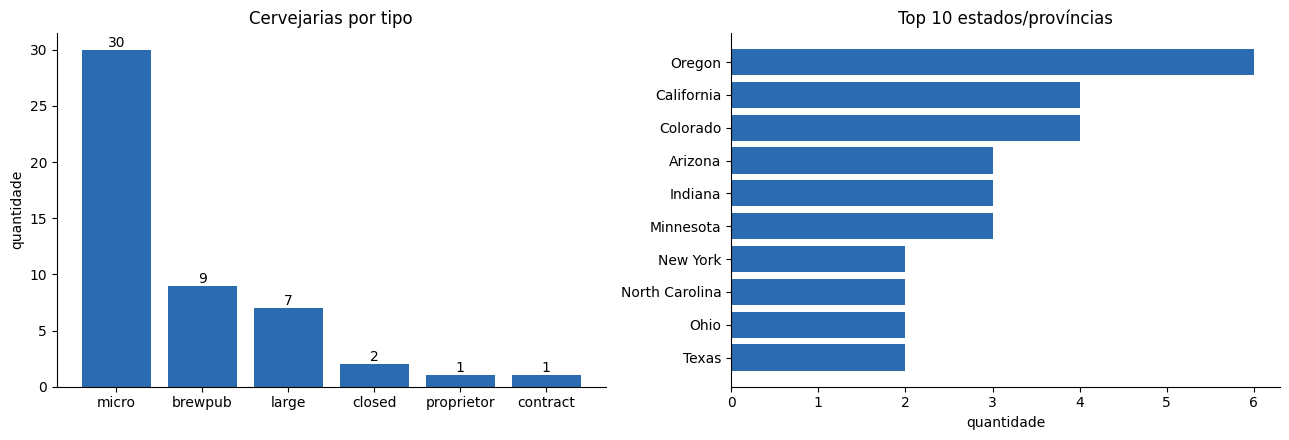

In [15]:
import matplotlib.pyplot as plt

gold = spark.read.format("delta").load(gold_path)

# agrega no Spark e só depois traz poucas linhas para o pandas
por_tipo = (gold.groupBy("brewery_type").agg(F.sum("brewery_count").alias("qtd"))
                .orderBy(F.desc("qtd")).toPandas())
por_estado = (gold.groupBy("state_province").agg(F.sum("brewery_count").alias("qtd"))
                  .orderBy(F.desc("qtd"), "state_province").limit(10).toPandas())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.bar(por_tipo["brewery_type"], por_tipo["qtd"], color="#2b6cb0")
ax1.set_title("Cervejarias por tipo")
ax1.set_ylabel("quantidade")
for x, y in zip(por_tipo["brewery_type"], por_tipo["qtd"]):
    ax1.text(x, y, str(y), ha="center", va="bottom")

ax2.barh(por_estado["state_province"][::-1], por_estado["qtd"][::-1], color="#2b6cb0")
ax2.set_title("Top 10 estados/províncias")
ax2.set_xlabel("quantidade")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

---
## ✅ Autoverificação

Rode esta célula antes de entregar. Ela confere **se os arquivos existem** e mostra as contagens. Ela não diz se o seu resultado está certo.

In [16]:
checagens = {
    "Bronze": os.path.join(base_path, "bronze", "bs_bronze_delta"),
    "Prata ": os.path.join(base_path, "silver", "breweries_silver"),
    "Ouro  ": os.path.join(base_path, "gold",   "breweries_por_local"),
}
for nome, caminho in checagens.items():
    try:
        n = spark.read.format("delta").load(caminho).count()
        print(f"✅ {nome}: {n:,} linhas  ({os.path.relpath(caminho, base_path)})")
    except Exception as e:
        print(f"❌ {nome}: não encontrada em {os.path.relpath(caminho, base_path)}")

print("\nLembrete: responda TODAS as perguntas ✏️ (Q1 a Q9, IA-1 e IA-2) antes de enviar.")

✅ Bronze: 50 linhas  (bronze/bs_bronze_delta)
✅ Prata : 50 linhas  (silver/breweries_silver)
✅ Ouro  : 48 linhas  (gold/breweries_por_local)

Lembrete: responda TODAS as perguntas ✏️ (Q1 a Q9, IA-1 e IA-2) antes de enviar.
